# <font color=darkred>Laboratory 13: Introduction to Numerical Methods </font>

In [1]:
# Preamble script block to identify host, user, and kernel
import sys
! hostname
! whoami
print(sys.executable)
print(sys.version)
print(sys.version_info)

zsh:1: command not found: hostname
jojo
/home/jojo/anaconda3/bin/python
3.14.6 | packaged by Anaconda, Inc. | (main, Jul  9 2026, 14:37:38) [GCC 14.3.0]
sys.version_info(major=3, minor=14, micro=6, releaselevel='final', serial=0)


## Full name: Dante Valenzuela
## R#: 12097254
## Title of the notebook: Laboratory 13 : Introduction to Numerical Methods
## Date: 10/23/26
___

In this lab you explore which tools and libraries are available in Python to compute derivatives and integrals. You will perform symbolic differentiation and integration with `SymPy` library and numerical differentiation and integration with `NumPy`.

## Lambda Function

A lambda function is a small, anonymous function defined using the lambda keyword. It can take any number of arguments but can only have one expression. They are often used for short, throwaway functions. It is suitable to use when you need a simple function for a short period and when defining functions inline without formally declaring them. Lambda functions are a powerful feature in Python that allows for concise function definitions.

### Syntax

lambda arguments: expression

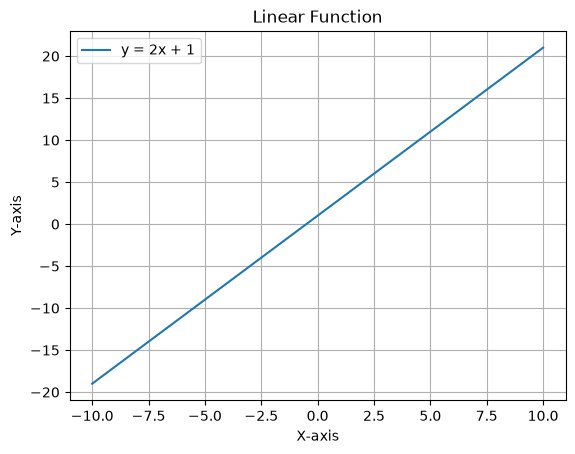

In [2]:
#EXAMPLE Linear function

import matplotlib.pyplot as plt
import numpy as np

# Define a linear function using lambda
linear_function = lambda x: 2 * x + 1

# Generate data
x = np.linspace(-10, 10, 100)
y = linear_function(x)

# Create a line plot
plt.plot(x, y, label='y = 2x + 1')
plt.title("Linear Function")
plt.xlabel("X-axis")
plt.ylabel("Y-axis")
plt.grid()
plt.legend()
plt.show()

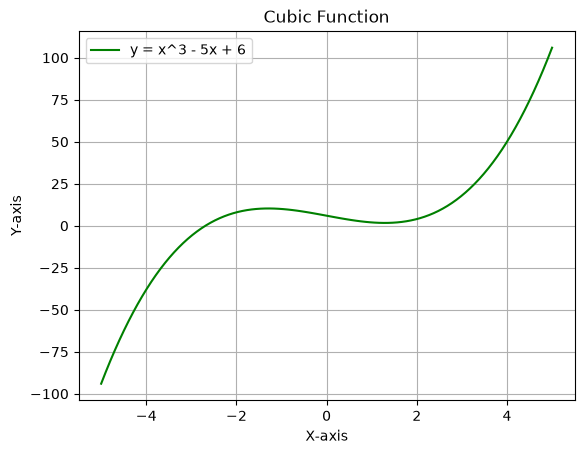

In [3]:
#EXAMPLE Cubic function
import matplotlib.pyplot as plt
import numpy as np

# Define a quadratic function using lambda
quadratic_function = lambda x: x**3 - 5 * x + 6

# Generate data
x = np.linspace(-5, 5, 100)
y = quadratic_function(x)

# Create a plot
plt.plot(x, y, label='y = x^3 - 5x + 6', color='green')
plt.title("Cubic Function")
plt.xlabel("X-axis")
plt.ylabel("Y-axis")
plt.grid()
plt.legend()
plt.show()

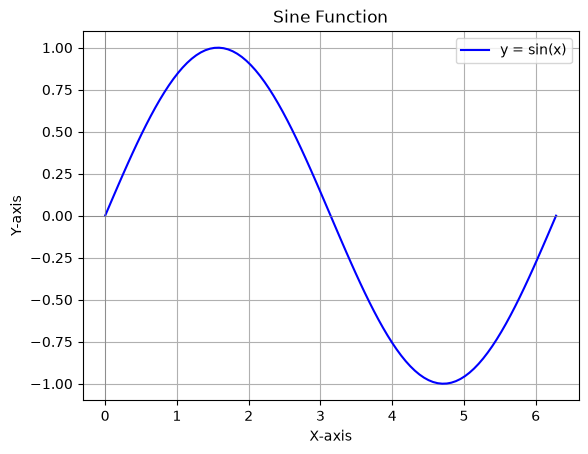

In [5]:
#EXAMPLE Trigonometric function
import matplotlib.pyplot as plt
import numpy as np

# Define a sine function using lambda
sine_function = lambda x: np.sin(x)

# Generate data
x = np.linspace(0, 2 * np.pi, 100)
y = sine_function(x)

# Create a plot
plt.plot(x, y, label='y = sin(x)', color='blue')
plt.title("Sine Function")
plt.xlabel("X-axis")
plt.ylabel("Y-axis")
plt.axhline(0, color='gray', lw=0.5)
plt.axvline(0, color='gray', lw=0.5)
plt.grid()
plt.legend()
plt.show()

## EXERCISE 13.1
1. Define a lambda function that represents a cubic polynomial: $y\left(x\right) = x^3-6x^2+9x$:
2. Use this lambda function to generate y values for x values ranging from -2 to 5 (inclusive) with an increment of 0.1.
3. Create a line plot to visualize the cubic function.
4. Add appropriate labels for the x-axis and y-axis, a title for the plot, and a grid for better readability.
5. Highlight the point where the function reaches its maximum value by adding a red dot and an annotation indicating the coordinates of this point.

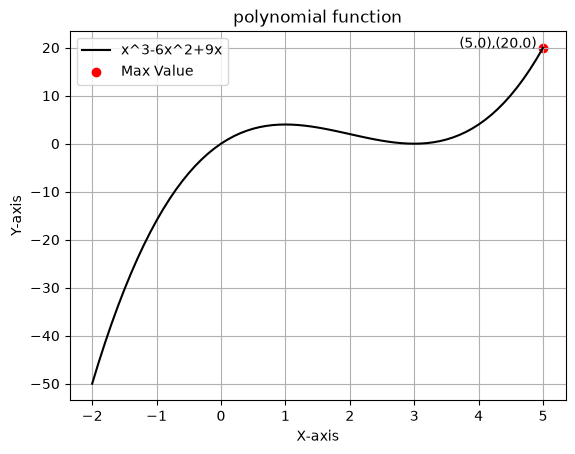

In [56]:
# Write your answer here
cubic_polynomial = lambda x: (x**3) - (6*(x**2)) + (9*x)

x= np.arange(-2, 5.1, 0.1)
y = cubic_polynomial(x)
maxv = np.argmax(y)
xc = x[maxv]
yc = y[maxv]

plt.plot(x,y, label="x^3-6x^2+9x", color = 'black')

plt.scatter(xc,yc, color = 'red', label = 'Max Value')
plt.annotate(f'({xc:.1f}),({yc:.1f})', xy=(xc,yc), xytext = (3.7,20))

plt.title('polynomial function')
plt.xlabel("X-axis")
plt.ylabel('Y-axis')
plt.legend()
plt.grid()

## Bisection Method

The Bisection Method is a simple and reliable method to find roots of a function $f(x)$ within a given interval [a,b]. It works under the assumption that the function changes sign over the interval, meaning f(a) and f(b) have opposite signs.

## Steps of the Bisection Method

1. **Choose an Interval**: Select two initial points \( a \) and \( b \) such that \( f(a) \) and \( f(b) \) have opposite signs.
2. **Calculate the Midpoint**: Compute the midpoint \( c = \frac{a + b}{2} \).
3. **Check the Root**:
   - If \( f(c) \) is close enough to zero, \( c \) is the root.
   - If \( f(a) \) and \( f(c) \) have opposite signs, set \( b = c \).
   - Otherwise, set \( a = c \).
4. **Repeat**: Continue the process until the desired accuracy is achieved.


In [14]:
#EXAMPLE
def bisection_method(f, a, b, es=1e-5):
    import numpy as np
    i=0
    c=(a+b)/2 #first guess
    ea=100 
    if f(a)*f(b)>0:
        return 'initial interval does not include solution'
#%% iterative
    while ea>es:     
        if f(a)*f(c)>0: 
            a=c
        else:
            b=c
        i=i+1
        old=c  #save old guess
        c=(a+b)/2 #new guess
        ea=abs((c-old)/c)*100 #relative error
        print(c,ea,i)
    return c
    print('The root lies at', c)

## Explanation of the Code

1. **Function Definition**: The `bisection_method` function takes the following parameters:
   -unc`: The function for which to find the root.
   - `a`: The lower bound of the interval.
   - `b`: The upper bound of the inte
   - .
es- `tol`: The tolerance for stopping the algorithm (default is \(1 \times 10^{-5 100).

2. **Sign Check**: The function checks whether \( f(a) \) and \( f(b) \) have opposite signs. If theyprints an errorlueError`.

3. **Main Loop**: The method calculates the midpoint \( c \) and evaluates the function at this point. Depending on the sign of \( f(c) \):
   - If \( f(c) \) is close to zero (within the specified tolerance), it returns \( c \) as the root and the number of iterations taken.
   - If \( f(a) \) and \( f(c) \) have opposite signs, it updates \( b \) to \( c \).
   - Otherwise, it updates \( a \) to \( c \).

4. **Stopping Condition**: The loop continues until the function value at \( c \) is within the specified tolerance or the maximum number of iterations is reached. If neither condition is met, a `ValueEresult is printed.

### Conclusion

This implementation of the Bisection Method provides a reliable way to find roots of continuous functions. You can easily modify the function and interval to explore different scenarios.


In [15]:
# Use of the function
bisection_method(lambda x: x**2-2,1,1.5,0.5)


1.375 9.090909090909092 1
1.4375 4.3478260869565215 2
1.40625 2.2222222222222223 3
1.421875 1.098901098901099 4
1.4140625 0.5524861878453038 5
1.41796875 0.27548209366391185 6


1.41796875

# EXERCISE 13.2
1. Define a lambda function that represents a cubic polynomial: $y\left(x\right) = x^3-2x+2$:
2. Use this lambda function to generate y values for x values ranging from -3 to 3 (inclusive) with an increment of 0.1.
3. Use the bisection_method function defined above to solve the root in the bracket of [-2,-1] with the default stopping criteria value.
4. Create a line plot to visualize the cubic function.
5. Add appropriate labels for the x-axis and y-axis, a title for the plot, and a grid for better readability.
6. Mark the root in the plot.

-1.75 14.285714285714285 1
-1.875 6.666666666666667 2
-1.8125 3.4482758620689653 3
-1.78125 1.7543859649122806 4
-1.765625 0.8849557522123894 5
-1.7734375 0.4405286343612335 6
-1.76953125 0.22075055187637968 7
-1.767578125 0.11049723756906078 8
-1.7685546875 0.05521811154058532 9
-1.76904296875 0.02760143527463428 10
-1.769287109375 0.013798813302056023 11
-1.7694091796875 0.006898930665746809 12
-1.76934814453125 0.0034495843250888264 13
-1.769317626953125 0.001724821912137572 14
-1.7693023681640625 0.0008624183936595001 15
-1.7692947387695312 0.0004312110562514823 16
-1.7692909240722656 0.000215605992984181 17
-1.7692928314208984 0.00010780288027735526 18
-1.769291877746582 5.3901469192345774e-05 19
-1.7692923545837402 2.6950727332753895e-05 20
-1.7692921161651611 1.347536548223145e-05 21
-1.7692922353744507 6.737682287152068e-06 22
-1.7692922353744507


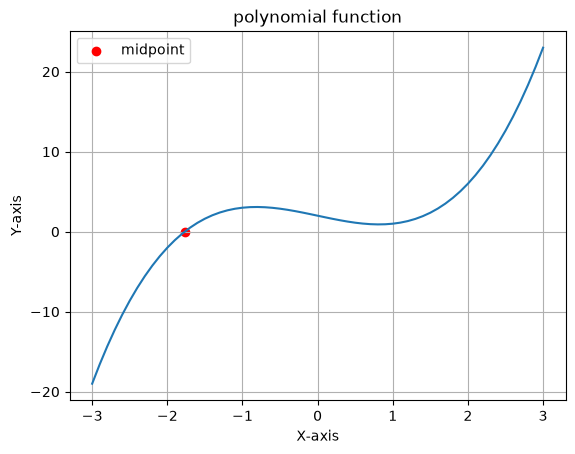

In [55]:
# Write your answer here
cubic_polynomial = lambda x: (x**3) - (2*x) + 2
x= np.arange(-3, 3.1, 0.1)
y = cubic_polynomial(x)
mid = bisection_method(cubic_polynomial,-2,-1)
midy = cubic_polynomial(mid)

plt.plot(x,y)

plt.scatter(mid,midy, color = 'red', label = 'midpoint')

plt.title('polynomial function')
plt.xlabel("X-axis")
plt.ylabel('Y-axis')
plt.legend()
plt.grid()

print(mid)




## Secant Method


The **Secant Method** is a numerical method used for finding the roots of a functionI it approximates the derivative using the values of the function at two points. The method assumes that the function is continuous and finds the root by iteratively approximating the secant line between two points on the curve. Secant method is an open root finding method so it does not need to bracket the root. Thus, it can diverge, to cover the divergence in the code we usually add a maximum number of iterations.e.

### Secant Method Formula:

Given two initial guesses \( x_0 \) and \( x_1 \), the next approximation \( x_2 \) is calculated using the formula:

\[
x_{n+1} = x_n - f(x_n) \cdot \frac{x_n - x_{n-1}}{f(x_n) - f(x_{n-1})}
\]

This process is repeated until the value of \( f(x_n) \) is close enough to zero (within a given tolerance), or the maximum number of iterations is reached.

### Steps to Implement the Secant Method in Python:

1. **Define the function** for which you want to find the root.
2. **Set initial guesses** for the root (i.e., \( x_0 \) and \( x_1 \)).
3. **Iterate using the Secant Method formula** until a root is found within a specified tolerance or the maximum number of iterations is reached.
4. **Return the root** if found or indicate that the method d not converge after {max_iter} iterations.")
    return None


In [51]:
#EXAMPLE
def secant_method(f, x0, x1, es=1e-6, maxiter=100):

    # Implements the Secant Method to find the root of a function f.
    
    # Parameters:
    # f         : function, the mathematical function for which to find the root
    # x0, x1    : float, initial guesses
    # es       : float, tolerance for convergence (default: 1e-6)
    # max_iter  : int, maximum number of iterations (default: 100)
    
    # Returns:
    # x2         : float, the approximated root
        
    #initialze
    ea=100
    i=0
    while ea>es and i<maxiter:
        i=i+1
        x2=x1-((f(x1)*(x0-x1))/(f(x0)-f(x1)))
        ea=abs((x2-x1)/x2)*100
        #update values
        x0=x1
        x1=x2
        print(x1,ea,i)
    #print results     
    if i==maxiter:
        print('Maximum number of iterations reached')
    else:
        print('The root lies at', x2)
        return x2
        

## Analysis and Tips:
### Initial Guesses: 
The choice of initial guesses x0 and x1 greatly affects the convergence of the method. If the guesses are too far from the root or the function is not well-behaved, the method may fail to converge.
### Tolerance and Iterations: 
The tolerance should be chosen carefully. A smaller tolerance gives a more accurate result but may require more iterations. The maximum number of iterations prevents the method from running indefinitely.
### Divergence: 
The method may fail to converge if the function has discontinuities, sharp corners, or the initial guesses are poorly chosen.
### Conclusion:
The Secant Method is a powerful tool for root finding when derivative information is unavailable or expensive to compute. While not as robust as some other methods (like bisection), it can be faster than methods like Newton's method under the right conditions.

In [52]:
# Use of the function
secant_method(lambda x: x**2-2,1,1.5)

1.4 7.1428571428571495 1
1.4137931034482758 0.9756097560975628 2
1.4142156862745099 0.029881073328164125 3
1.4142135620573204 0.0001502048379730332 4
1.4142135623730947 2.2328614574358295e-08 5
The root lies at 1.4142135623730947


1.4142135623730947

# EXERCISE 13.3
1. Define a lambda function that represents a cubic polynomial: $y\left(x\right) = x^3-2x+2$:
2. Use the lambda function to generate y values for x values ranging from -3 to 3 (inclusive) with an increment of 0.1.
3. Use the secant_method function defined above to solve the root with initial guesses of [-2,-1] with the default stopping criteria value.
4. Create a line plot to visualize the cubic function.
5. Add appropriate labels for the x-axis and y-axis, a title for the plot, and a grid for better readability.
6. Mark the root in the plot.

-1.6 37.50000000000001 1
-1.9493670886075947 17.922077922077907 2
-1.7476129346292872 11.544556004393764 3
-1.7667091236612862 1.0808903840618909 4
-1.7693330950556518 0.14830284934466345 5
-1.7692922785579854 0.0023069392299430347 6
-1.7692923542364172 4.277327687665202e-06 7
-1.7692923542386314 1.2514770637016897e-10 8
The root lies at -1.7692923542386314


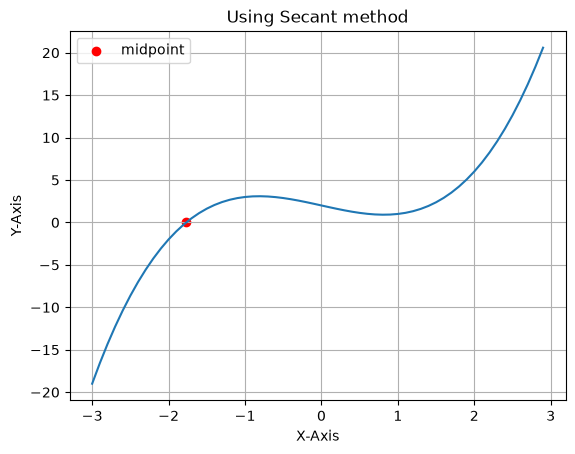

In [53]:
#Write your answer here:
f = lambda x: (x**3)-(2*x)+2
x = np.arange(-3,3,0.1)
y = f(x)
plt.plot(x,y)

root = secant_method(f,-2,-1)
rooty = f(root)

plt.scatter(root,rooty, color = 'red', label = 'midpoint')

plt.xlabel('X-Axis')
plt.ylabel('Y-Axis')
plt.title('Using Secant method')

plt.grid()
plt.legend()


